# Projekt 2: Human Activity Recognition - MLP w PyTorch

**Cel:** sprawdzic, jak gesty perceptron wielowarstwowy zaimplementowany w
PyTorch klasyfikuje aktywnosc czlowieka na podstawie gotowych cech UCI HAR.

Notebook wykorzystuje wektory `561` cech wyliczonych z okien sygnalow
akcelerometru i zyroskopu. Oryginalny test HAR obejmuje inne osoby niz train,
dlatego pozostaje koncowym zbiorem oceny modelu.

## Plan eksperymentu

1. Wczytanie danych HAR i kontrola dostarczonego splitu.
2. Podzial danych treningowych na train/validation po identyfikatorze osoby.
3. Standaryzacja cech dopasowana tylko na wlasciwym train.
4. Trening kilku architektur MLP w PyTorch z `DataLoader`, `CrossEntropyLoss`
   i early stopping.
5. Wybor wariantu na podstawie walidacji, ponowny trening na calym train i
   ewaluacja na oryginalnym tescie HAR.

Model korzysta z `cuda`, gdy PyTorch widzi karte GPU.

In [1]:
from copy import deepcopy
from pathlib import Path
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

HAR_ROOT = (
    Path("human+activity+recognition+using+smartphones")
    / "UCI HAR Dataset"
    / "UCI HAR Dataset"
)
assert HAR_ROOT.exists(), f"Nie znaleziono katalogu HAR: {HAR_ROOT.resolve()}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Katalog danych: {HAR_ROOT.resolve()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA build: {torch.version.cuda}")
print(f"Urzadzenie treningowe: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Katalog danych: C:\Users\piotr\Desktop\Bartman SI\Projekt 2\human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset
PyTorch: 2.12.0+cu132
CUDA build: 13.2
Urzadzenie treningowe: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


## 1. Dane HAR

In [2]:
activity_labels = pd.read_csv(
    HAR_ROOT / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"],
)
activity_map = dict(zip(activity_labels["activity_id"], activity_labels["activity"]))

features = pd.read_csv(
    HAR_ROOT / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_index", "feature_name"],
)
feature_columns = [
    f"f{feature_index:03d}_{feature_name}"
    for feature_index, feature_name in zip(features["feature_index"], features["feature_name"])
]

def read_vector(path, column_name):
    return pd.read_csv(path, sep=r"\s+", header=None, names=[column_name])[column_name]

X_train_df = pd.read_csv(HAR_ROOT / "train" / "X_train.txt", sep=r"\s+", header=None, names=feature_columns)
X_test_df = pd.read_csv(HAR_ROOT / "test" / "X_test.txt", sep=r"\s+", header=None, names=feature_columns)
y_train_ids = read_vector(HAR_ROOT / "train" / "y_train.txt", "activity_id").astype(int)
y_test_ids = read_vector(HAR_ROOT / "test" / "y_test.txt", "activity_id").astype(int)
subject_train = read_vector(HAR_ROOT / "train" / "subject_train.txt", "subject_id").astype(int)
subject_test = read_vector(HAR_ROOT / "test" / "subject_test.txt", "subject_id").astype(int)

# CrossEntropyLoss oczekuje klas 0..C-1.
y_train_zero = y_train_ids.to_numpy(dtype=np.int64) - 1
y_test_zero = y_test_ids.to_numpy(dtype=np.int64) - 1

summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "windows": [len(X_train_df), len(X_test_df)],
        "features": [X_train_df.shape[1], X_test_df.shape[1]],
        "subjects": [subject_train.nunique(), subject_test.nunique()],
        "missing_values": [int(X_train_df.isna().sum().sum()), int(X_test_df.isna().sum().sum())],
        "min_feature_value": [X_train_df.min().min(), X_test_df.min().min()],
        "max_feature_value": [X_train_df.max().max(), X_test_df.max().max()],
    }
)

display(summary.round(4))
print(f"Aktywnosci: {activity_map}")
print(f"Osoby train: {sorted(subject_train.unique())}")
print(f"Osoby test:  {sorted(subject_test.unique())}")
print(f"Czesc wspolna osob: {sorted(set(subject_train.unique()) & set(subject_test.unique()))}")
X_train_df.iloc[:5, :8]

,split,windows,features,subjects,missing_values,min_feature_value,max_feature_value
0,train,7352,561,21,0,-1.0,1.0
1,test,2947,561,9,0,-1.0,1.0


Aktywnosci: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}
Osoby train: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Osoby test:  [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Czesc wspolna osob: []


,f001_tBodyAcc-mean()-X,f002_tBodyAcc-mean()-Y,f003_tBodyAcc-mean()-Z,f004_tBodyAcc-std()-X,f005_tBodyAcc-std()-Y,f006_tBodyAcc-std()-Z,f007_tBodyAcc-mad()-X,f008_tBodyAcc-mad()-Y
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672


,split,activity_id,activity,windows,share_percent
0,train,1,WALKING,1226,16.7
1,train,2,WALKING_UPSTAIRS,1073,14.6
2,train,3,WALKING_DOWNSTAIRS,986,13.4
3,train,4,SITTING,1286,17.5
4,train,5,STANDING,1374,18.7
5,train,6,LAYING,1407,19.1
6,test,1,WALKING,496,16.8
7,test,2,WALKING_UPSTAIRS,471,16.0
8,test,3,WALKING_DOWNSTAIRS,420,14.3
9,test,4,SITTING,491,16.7


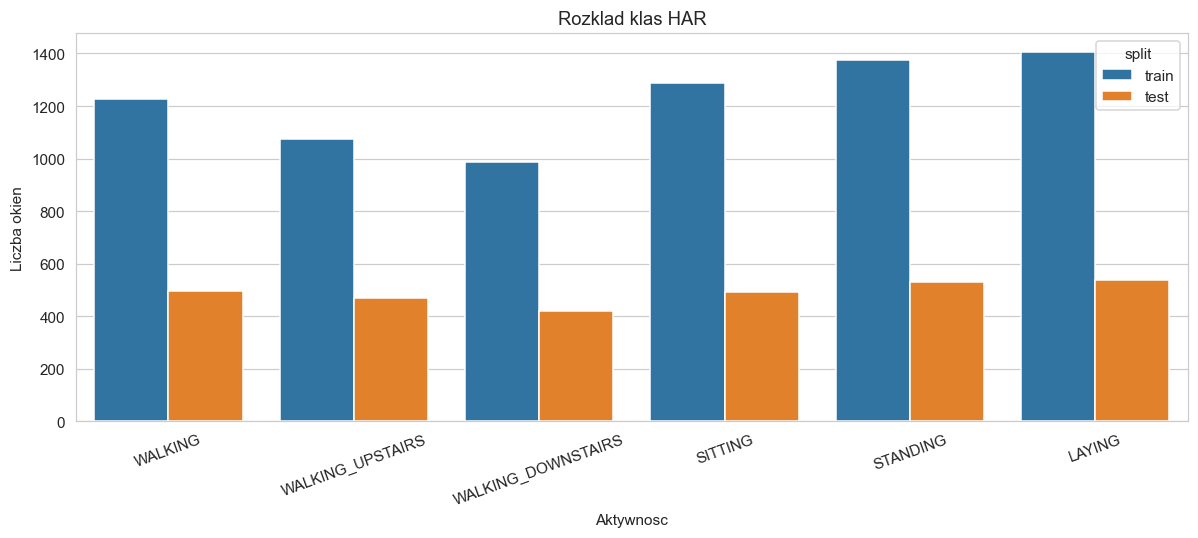

In [3]:
def class_count_table(labels, split_name):
    counts = labels.value_counts().sort_index()
    return pd.DataFrame(
        {
            "split": split_name,
            "activity_id": counts.index,
            "activity": [activity_map[class_id] for class_id in counts.index],
            "windows": counts.values,
            "share_percent": (counts.values / counts.values.sum() * 100).round(1),
        }
    )

class_counts = pd.concat(
    [class_count_table(y_train_ids, "train"), class_count_table(y_test_ids, "test")],
    ignore_index=True,
)
display(class_counts)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=class_counts, x="activity", y="windows", hue="split", ax=ax)
ax.set_title("Rozklad klas HAR")
ax.set_xlabel("Aktywnosc")
ax.set_ylabel("Liczba okien")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 2. Walidacja po osobach i preprocessing

Oryginalny test zostaje nietkniety. Z train wydzielamy jeden fold walidacyjny
przez `StratifiedGroupKFold`, aby okna tej samej osoby nie trafily jednoczesnie
do czesci uczacej i walidacyjnej.

In [4]:
splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
fit_indices, val_indices = next(
    splitter.split(X_train_df, y_train_zero, groups=subject_train.to_numpy())
)

X_fit_df = X_train_df.iloc[fit_indices]
X_val_df = X_train_df.iloc[val_indices]
y_fit = y_train_zero[fit_indices]
y_val = y_train_zero[val_indices]
fit_subjects = subject_train.iloc[fit_indices]
val_subjects = subject_train.iloc[val_indices]

scaler = StandardScaler()
X_fit = scaler.fit_transform(X_fit_df).astype(np.float32)
X_val = scaler.transform(X_val_df).astype(np.float32)

print(f"Fit: {X_fit.shape}, validation: {X_val.shape}")
print(f"Osoby fit: {sorted(fit_subjects.unique())}")
print(f"Osoby validation: {sorted(val_subjects.unique())}")
print(f"Czesc wspolna osob fit/validation: {sorted(set(fit_subjects) & set(val_subjects))}")
print("Rozklad validation:")
print(pd.Series(y_val + 1).value_counts().sort_index().rename(index=activity_map))

Fit: (5563, 561), validation: (1789, 561)
Osoby fit: [np.int64(1), np.int64(3), np.int64(5), np.int64(7), np.int64(8), np.int64(14), np.int64(15), np.int64(16), np.int64(19), np.int64(22), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Osoby validation: [np.int64(6), np.int64(11), np.int64(17), np.int64(21), np.int64(23)]
Czesc wspolna osob fit/validation: []
Rozklad validation:
WALKING               288
WALKING_UPSTAIRS      251
WALKING_DOWNSTAIRS    239
SITTING               325
STANDING              339
LAYING                347
Name: count, dtype: int64


In [5]:
def make_loader(X, y, batch_size, shuffle):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    generator = torch.Generator().manual_seed(RANDOM_STATE)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)

fit_loader = make_loader(X_fit, y_fit, batch_size=256, shuffle=True)
val_loader = make_loader(X_val, y_val, batch_size=512, shuffle=False)

print(f"Batchy fit: {len(fit_loader)}, batchy validation: {len(val_loader)}")

Batchy fit: 22, batchy validation: 4


## 3. Architektura i funkcje treningowe PyTorch

In [6]:
class HarMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout, num_classes):
        super().__init__()
        layers = []
        previous_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend(
                [
                    nn.Linear(previous_dim, hidden_dim),
                    nn.BatchNorm1d(hidden_dim),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                ]
            )
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def collect_predictions(model, loader):
    model.eval()
    all_true = []
    all_pred = []
    with torch.no_grad():
        for features_batch, labels_batch in loader:
            features_batch = features_batch.to(DEVICE)
            logits = model(features_batch)
            predictions = logits.argmax(dim=1).cpu().numpy()
            all_true.append(labels_batch.numpy())
            all_pred.append(predictions)
    return np.concatenate(all_true), np.concatenate(all_pred)


def evaluate_loader(model, loader, loss_function):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    with torch.no_grad():
        for features_batch, labels_batch in loader:
            features_batch = features_batch.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            logits = model(features_batch)
            loss = loss_function(logits, labels_batch)
            total_loss += loss.item() * len(labels_batch)
            total_examples += len(labels_batch)
    y_true, y_pred = collect_predictions(model, loader)
    return {
        "loss": total_loss / total_examples,
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }


def train_with_early_stopping(config, train_loader, validation_loader, input_dim, num_classes):
    model = HarMLP(
        input_dim=input_dim,
        hidden_dims=config["hidden_dims"],
        dropout=config["dropout"],
        num_classes=num_classes,
    ).to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )

    history = []
    best_state = None
    best_val_f1 = -np.inf
    wait = 0

    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        train_loss_total = 0.0
        train_examples = 0

        for features_batch, labels_batch in train_loader:
            features_batch = features_batch.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features_batch)
            loss = loss_function(logits, labels_batch)
            loss.backward()
            optimizer.step()
            train_loss_total += loss.item() * len(labels_batch)
            train_examples += len(labels_batch)

        train_true, train_pred = collect_predictions(model, train_loader)
        validation_metrics = evaluate_loader(model, validation_loader, loss_function)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss_total / train_examples,
                "train_f1_macro": f1_score(train_true, train_pred, average="macro"),
                "val_loss": validation_metrics["loss"],
                "val_accuracy": validation_metrics["accuracy"],
                "val_f1_macro": validation_metrics["f1_macro"],
            }
        )

        if validation_metrics["f1_macro"] > best_val_f1 + config["min_delta"]:
            best_val_f1 = validation_metrics["f1_macro"]
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= config["patience"]:
                break

    model.load_state_dict(best_state)
    history_df = pd.DataFrame(history)
    return model, history_df, best_val_f1


print(HarMLP(input_dim=X_fit.shape[1], hidden_dims=(128, 64), dropout=0.2, num_classes=6))

HarMLP(
  (network): Sequential(
    (0): Linear(in_features=561, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=6, bias=True)
  )
)


## 4. Porownanie kilku konfiguracji MLP

In [7]:
candidate_configs = [
    {
        "name": "MLP_64",
        "hidden_dims": (64,),
        "dropout": 0.10,
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "max_epochs": 160,
        "patience": 18,
        "min_delta": 1e-4,
    },
    {
        "name": "MLP_128_64",
        "hidden_dims": (128, 64),
        "dropout": 0.20,
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "max_epochs": 160,
        "patience": 18,
        "min_delta": 1e-4,
    },
    {
        "name": "MLP_256_128",
        "hidden_dims": (256, 128),
        "dropout": 0.25,
        "learning_rate": 5e-4,
        "weight_decay": 1e-3,
        "max_epochs": 180,
        "patience": 20,
        "min_delta": 1e-4,
    },
]

candidate_models = {}
candidate_histories = {}
candidate_rows = []

for config in candidate_configs:
    print(f"Trening {config['name']} na {DEVICE}...")
    model, history, best_val_f1 = train_with_early_stopping(
        config=config,
        train_loader=fit_loader,
        validation_loader=val_loader,
        input_dim=X_fit.shape[1],
        num_classes=len(activity_map),
    )
    candidate_models[config["name"]] = model
    candidate_histories[config["name"]] = history
    candidate_rows.append(
        {
            "config": config["name"],
            "hidden_dims": config["hidden_dims"],
            "dropout": config["dropout"],
            "learning_rate": config["learning_rate"],
            "weight_decay": config["weight_decay"],
            "epochs_run": int(history["epoch"].iloc[-1]),
            "best_val_f1_macro": best_val_f1,
        }
    )

candidate_results = pd.DataFrame(candidate_rows).sort_values("best_val_f1_macro", ascending=False)
candidate_results.round(4)

Trening MLP_64 na cuda...


Trening MLP_128_64 na cuda...


Trening MLP_256_128 na cuda...


,config,hidden_dims,dropout,learning_rate,weight_decay,epochs_run,best_val_f1_macro
0,MLP_64,"(64,)",0.10,0.0010,0.0001,81,0.9649
2,MLP_256_128,"(256, 128)",0.25,0.0005,0.0010,71,0.9629
1,MLP_128_64,"(128, 64)",0.20,0.0010,0.0001,51,0.9593


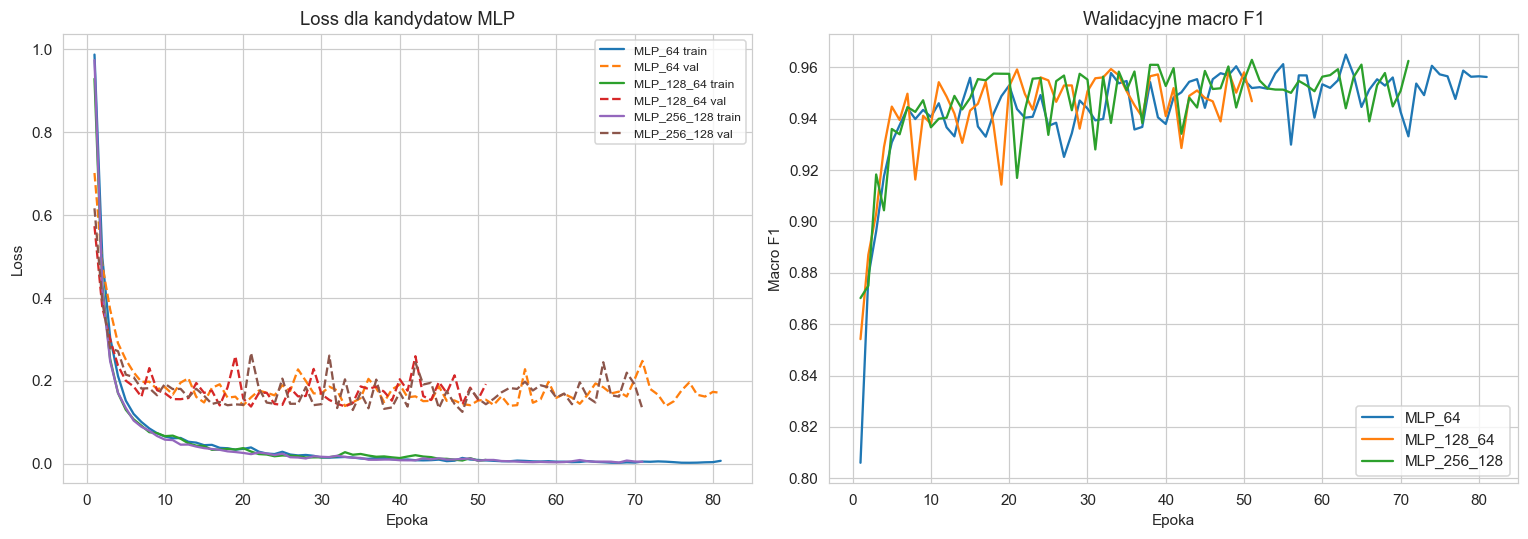

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for config_name, history in candidate_histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=f"{config_name} train")
    axes[0].plot(history["epoch"], history["val_loss"], linestyle="--", label=f"{config_name} val")
    axes[1].plot(history["epoch"], history["val_f1_macro"], label=config_name)

axes[0].set_title("Loss dla kandydatow MLP")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[1].set_title("Walidacyjne macro F1")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Finalny trening na pelnym train

Po wyborze konfiguracji wykorzystujemy caly dostarczony train. Liczbe epok
ustalamy na podstawie epoki najlepszego wyniku walidacyjnego wybranego modelu,
aby nie podgladac testu przy decyzji o czasie treningu.

In [9]:
best_config_name = candidate_results.iloc[0]["config"]
best_config = next(config for config in candidate_configs if config["name"] == best_config_name)
best_history = candidate_histories[best_config_name]
best_epoch_from_validation = int(best_history.loc[best_history["val_f1_macro"].idxmax(), "epoch"])
final_epochs = max(best_epoch_from_validation, 10)

full_scaler = StandardScaler()
X_train_full = full_scaler.fit_transform(X_train_df).astype(np.float32)
X_test_full = full_scaler.transform(X_test_df).astype(np.float32)
full_train_loader = make_loader(X_train_full, y_train_zero, batch_size=256, shuffle=True)
test_loader = make_loader(X_test_full, y_test_zero, batch_size=512, shuffle=False)

final_model = HarMLP(
    input_dim=X_train_full.shape[1],
    hidden_dims=best_config["hidden_dims"],
    dropout=best_config["dropout"],
    num_classes=len(activity_map),
).to(DEVICE)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=best_config["learning_rate"],
    weight_decay=best_config["weight_decay"],
)

final_history = []
for epoch in range(1, final_epochs + 1):
    final_model.train()
    loss_total = 0.0
    examples = 0
    for features_batch, labels_batch in full_train_loader:
        features_batch = features_batch.to(DEVICE)
        labels_batch = labels_batch.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = final_model(features_batch)
        loss = loss_function(logits, labels_batch)
        loss.backward()
        optimizer.step()
        loss_total += loss.item() * len(labels_batch)
        examples += len(labels_batch)
    final_history.append({"epoch": epoch, "train_loss": loss_total / examples})

print(f"Wybrana konfiguracja: {best_config_name}")
print(f"Najlepsza epoka walidacyjna: {best_epoch_from_validation}")
print(f"Epoki finalnego treningu: {final_epochs}")

Wybrana konfiguracja: MLP_64
Najlepsza epoka walidacyjna: 63
Epoki finalnego treningu: 63


## 6. Ewaluacja na oryginalnym tescie HAR

In [10]:
test_true_zero, test_pred_zero = collect_predictions(final_model, test_loader)
test_true_ids = test_true_zero + 1
test_pred_ids = test_pred_zero + 1

def metric_row(model_name, y_true, y_pred):
    per_class = f1_score(y_true, y_pred, labels=sorted(activity_map), average=None)
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro"),
        "Recall_macro": recall_score(y_true, y_pred, average="macro"),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    row.update(
        {
            f"F1_{activity_map[class_id]}": score
            for class_id, score in zip(sorted(activity_map), per_class)
        }
    )
    return row

test_metrics = pd.DataFrame(
    [metric_row(f"PyTorch {best_config_name}", test_true_ids, test_pred_ids)]
).set_index("Model")
test_metrics.round(4)

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_WALKING,F1_WALKING_UPSTAIRS,F1_WALKING_DOWNSTAIRS,F1_SITTING,F1_STANDING,F1_LAYING
Model,,,,,,,,,,
PyTorch MLP_64,0.9535,0.9584,0.9538,0.9549,0.9773,0.9722,0.9855,0.9101,0.9083,0.9762


Classification report - finalny MLP PyTorch
                    precision    recall  f1-score   support

           WALKING       0.96      1.00      0.98       496
  WALKING_UPSTAIRS       0.98      0.96      0.97       471
WALKING_DOWNSTAIRS       1.00      0.97      0.99       420
           SITTING       0.96      0.87      0.91       491
          STANDING       0.86      0.97      0.91       532
            LAYING       1.00      0.96      0.98       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



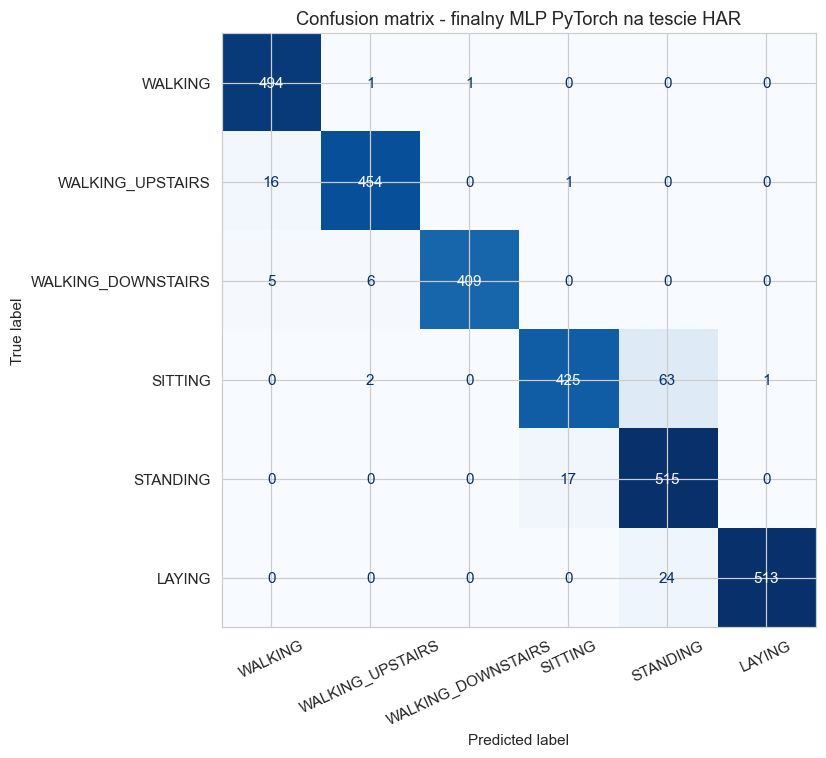

In [11]:
target_names = [activity_map[class_id] for class_id in sorted(activity_map)]
print("Classification report - finalny MLP PyTorch")
print(classification_report(test_true_ids, test_pred_ids, target_names=target_names))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    test_true_ids,
    test_pred_ids,
    labels=sorted(activity_map),
    display_labels=target_names,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=25,
    ax=ax,
)
ax.set_title("Confusion matrix - finalny MLP PyTorch na tescie HAR")
plt.tight_layout()
plt.show()

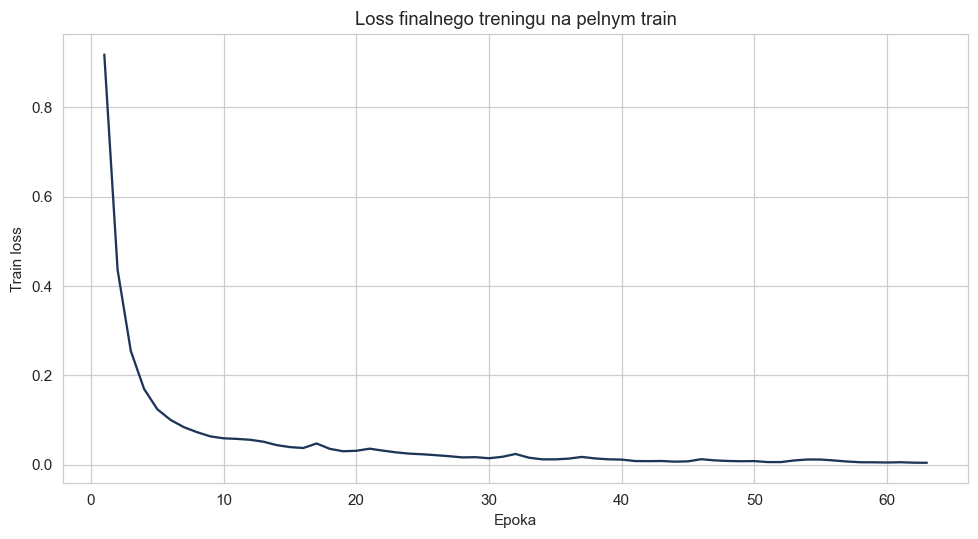

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
final_history_df = pd.DataFrame(final_history)
ax.plot(final_history_df["epoch"], final_history_df["train_loss"], color="#1d3557")
ax.set_title("Loss finalnego treningu na pelnym train")
ax.set_xlabel("Epoka")
ax.set_ylabel("Train loss")
plt.tight_layout()
plt.show()

## 7. Wnioski

Implementacja MLP w PyTorch potwierdzila, ze UCI HAR jest bardzo dobrym
zbiorem do projektu sieci neuronowej. Model pracowal na `561` cechach opisujacych
okna sygnalow z akcelerometru i zyroskopu. Zachowano oryginalny test HAR z innymi
osobami niz w train, a dodatkowa walidacja architektur zostala wydzielona z train
przez `StratifiedGroupKFold` po identyfikatorze osoby. Ogranicza to ryzyko
zawyzenia wynikow przez uczenie i walidacje na oknach tej samej osoby.

### Wynik modelu PyTorch

PyTorch poprawnie wykorzystal GPU (`cuda`, `NVIDIA GeForce RTX 5070 Ti`). Z trzech
sprawdzonych wariantow najlepsza walidacyjnie okazala sie najprostsza siec
`MLP_64` z jedna warstwa ukryta `(64,)`, dropout `0.10`, learning rate `0.001`
i weight decay `0.0001`. Na walidacji po osobach osiagnela ona
`macro F1 = 0.9649`. Finalny model uczony na calym train przez `63` epoki uzyskal
na oryginalnym tescie `accuracy = 0.9535` oraz `macro F1 = 0.9549`.

Wieksze architektury `(128, 64)` i `(256, 128)` nie poprawily wyniku walidacyjnego.
W tym zadaniu wazniejsze okazalo sie stabilne dopasowanie do gotowych cech HAR
niz zwiekszanie liczby neuronow.

### Jakosc klasyfikacji

Finalny MLP bardzo dobrze rozpoznawal aktywnosci dynamiczne: `F1` wynioslo
`0.98` dla `WALKING`, `0.97` dla `WALKING_UPSTAIRS` i `0.99` dla
`WALKING_DOWNSTAIRS`. Bardzo wysoki wynik uzyskano tez dla `LAYING`
(`F1 = 0.98`). Najtrudniejsze pozostaly aktywnosci statyczne `SITTING`
i `STANDING`, obie z wynikiem `F1` okolo `0.91`. Raport pokazuje zwlaszcza
nizszy recall dla `SITTING` (`0.87`) i nizsza precision dla `STANDING` (`0.86`),
co wskazuje na ich wzajemne pomylki.

### Porownanie z notebookiem sklearn

Wersja PyTorch uzyskala lepszy wynik testowy niz wczesniejszy notebook oparty
na `MLPClassifier` ze sklearn (`macro F1 = 0.9549` wobec `0.9434`). Jednoczesnie
PyTorch pokazuje bardziej klasyczny przebieg pracy z siecia neuronowa: jawna
architekture `nn.Module`, `DataLoader`, funkcje straty, optimizer, epoki,
early stopping i trening na GPU. Z tych powodow jest mocniejszym kandydatem
na finalna wersje projektu MLP.